# QA review of the full run

Reads the per-shot results of `scripts/run_qa.py` from `reports/qa/` and opens a few
shots with `fusion_eq.io.load_shot`. Cells are run manually, top to bottom. Derived
quantities and thresholds are defined in the cell that uses them.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fusion_eq.io import load_shot

REPORT_DIR = Path("../reports/qa")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

qa = pd.read_parquet(REPORT_DIR / "qa_per_shot.parquet")
run = json.loads((REPORT_DIR / "qa_run.json").read_text())
SPLITS = ["diii_d_train", "diii_d_public_test", "mast_public_test", "mast_samples"]
qa["split"] = pd.Categorical(qa["split"], SPLITS)

print(f"run {run['timestamp']}, commit {run['repo_commit'][:10]}, {run['runtime_s']:.0f} s")
print(qa.groupby("split", observed=True).size())
print("shots with errors:", int(qa["error"].notna().sum()))

run 2026-10-06T00:00:55+00:00, commit cd19432ce6, 102 s
split
diii_d_train          7041
diii_d_public_test     874
mast_public_test      1206
mast_samples             3
dtype: int64
shots with errors: 0


## 1. Hardware markers by split

Ip time-axis fix rate, magnetics sampling interval and length, Thomson channel
counts. These tell the acquisition populations apart before any modelling.

What the output shows. DIII-D coil currents were recorded at two rates: 20 kHz on 5,518 shots
and 2 kHz on 2,397, while MAST records at 5 kHz throughout (F10). The organizers' Ip fix
corrects the 20 kHz shots and leaves the 2 kHz shots untouched, which is the crosstab in the
second cell. DIII-D test shots match training shots on every marker: 20 kHz share 70.0 percent
against 67.0 percent, 44-channel core Thomson 89.9 against 90.4 percent, 10-channel edge
Thomson 90.7 against 91.9 percent, positive Ip after the alignment 91.2 against 91.3 percent
(F08). Channel layouts vary by shot and by machine, so
Thomson enters the model as profile descriptors rather than one column per channel (F16).


In [2]:
def counts_by_split(column, decimals=None):
    values = qa[column]
    if decimals is not None:
        values = values.round(decimals)
    table = pd.crosstab(qa["split"], values, dropna=False)
    return table.loc[:, (table != 0).any()]

ip_fix = qa[qa["machine"] == "DIII-D"].groupby("split", observed=True)["ip_fix_applied"].agg(
    shots="size", corrected="sum", rate="mean")
display(ip_fix)
display(counts_by_split("time_magnetics_dt_median_ms", decimals=3))
display(counts_by_split("time_magnetics_n"))
display(counts_by_split("tsm_core_n_channels"))
display(counts_by_split("tsm_edge_n_channels"))

,shots,corrected,rate
split,,,
diii_d_train,7041,4930,0.700185
diii_d_public_test,874,586,0.670481


time_magnetics_dt_median_ms,0.05,0.20,0.50
split,,,
diii_d_train,4932,0,2109
diii_d_public_test,586,0,288
mast_public_test,0,1206,0
mast_samples,0,3,0


time_magnetics_n,15482.0,30000.0,49152.0,50172.0,50176.0,327680.0,480256.0,501760.0
split,,,,,,,,
diii_d_train,0,0,1154,1,954,5,4925,2
diii_d_public_test,0,0,143,0,145,0,586,0
mast_public_test,114,1092,0,0,0,0,0,0
mast_samples,0,3,0,0,0,0,0,0


tsm_core_n_channels,40.0,42.0,43.0,44.0,54.0,130.0
split,,,,,,
diii_d_train,218,438,1,6327,57,0
diii_d_public_test,31,40,0,790,13,0
mast_public_test,0,0,0,0,0,1206
mast_samples,0,0,0,0,0,3


tsm_edge_n_channels,10.0,14.0,16.0
split,,,
diii_d_train,6385,656,0
diii_d_public_test,803,71,0
mast_public_test,0,0,1206
mast_samples,0,0,3


In [3]:
# Do the 2 kHz DIII-D shots coincide with the shots whose Ip axis shipped correct
d3d = qa[qa["machine"] == "DIII-D"].copy()
d3d["magnetics_rate"] = np.where(d3d["time_magnetics_dt_median_ms"] > 0.1, "2 kHz", "20 kHz")
display(pd.crosstab([d3d["split"], d3d["magnetics_rate"]], d3d["ip_fix_applied"].astype("boolean"),
                    margins=True))
display(pd.crosstab(d3d["magnetics_rate"], d3d["tsm_core_n_channels"]))

ip_fix_applied                     False  True   All
split              magnetics_rate                   
diii_d_train       2 kHz            2109     0  2109
                   20 kHz              2  4930  4932
diii_d_public_test 2 kHz             288     0   288
                   20 kHz              0   586   586
All                                 2399  5516  7915

tsm_core_n_channels,40.0,42.0,43.0,44.0,54.0
magnetics_rate,,,,,
2 kHz,0,0,0,2397,0
20 kHz,249,478,1,4720,70


## 2. Thomson coverage inside the EFIT window

Coverage is the fraction of EFIT frames with a valid core profile (at least half
the channels carry both Te and ne) within 20 ms. The "any channel" variant needs one
valid channel only.

What the output shows. About 97 percent of shots have a valid core profile within 20 ms of at
least 90 percent of their frames. No valid profile at all occurs on 53 training shots, 6 DIII-D
test shots and 1 MAST test shot; no Thomson channel at all on 11 training shots and 1 DIII-D
test shot (F17). Coverage depends on the time tolerance, most of all on MAST: tightening it
from 20 ms to 10 ms raises the MAST shots below 90 percent coverage from 49 to 331 (F18).
Consequences: features are built from the valid channels, Thomson is interpolated in time
between valid profiles, and the model needs a defined behaviour when Thomson is missing.


In [4]:
COVERAGE = "tsm_core_frames_valid_within_20ms"
COVERAGE_ANY = "tsm_core_frames_any_within_20ms"

def coverage_counts(column):
    v = qa[column]
    return qa.assign(
        below_0p9=v < 0.9, below_0p5=v < 0.5, zero=v == 0, missing=v.isna(),
    ).groupby("split", observed=True)[["below_0p9", "below_0p5", "zero", "missing"]].sum()

print("valid profile within 20 ms")
display(coverage_counts(COVERAGE))
print("any valid channel within 20 ms")
display(coverage_counts(COVERAGE_ANY))
print("valid profile within 10 ms")
display(coverage_counts("tsm_core_frames_valid_within_10ms"))

valid profile within 20 ms


,below_0p9,below_0p5,zero,missing
split,,,,
diii_d_train,222,82,53,15
diii_d_public_test,26,11,6,0
mast_public_test,49,3,1,0
mast_samples,0,0,0,0


any valid channel within 20 ms


,below_0p9,below_0p5,zero,missing
split,,,,
diii_d_train,33,17,11,15
diii_d_public_test,5,2,1,0
mast_public_test,46,0,0,0
mast_samples,0,0,0,0


valid profile within 10 ms


,below_0p9,below_0p5,zero,missing
split,,,,
diii_d_train,474,120,53,15
diii_d_public_test,51,13,6,0
mast_public_test,331,9,1,0
mast_samples,0,0,0,0


,split,shot,time_n_frames,tsm_core_n_channels,tsm_core_frames_valid_within_20ms,tsm_core_frames_any_within_20ms,tsm_core_slice_all_missing_frac,tsm_core_n_times_window
3442,diii_d_train,5a79f2123a,289.0,44.0,0.0,0.000000,1.000000,1023.0
3144,diii_d_train,4fc55655ce,3.0,44.0,0.0,1.000000,0.166667,12.0
1914,diii_d_train,24c69eb2c7,87.0,44.0,0.0,1.000000,0.000000,273.0
7502,diii_d_train,f0a33e7fe4,2.0,44.0,0.0,1.000000,0.000000,5.0
2210,diii_d_train,2e5863d2fb,35.0,44.0,0.0,1.000000,0.000000,160.0
993,diii_d_train,043557db5d,310.0,44.0,0.0,0.000000,1.000000,1391.0
6973,diii_d_train,dc455b3150,2.0,44.0,0.0,1.000000,0.000000,6.0
4500,diii_d_train,8248019dd3,86.0,44.0,0.0,1.000000,0.000000,288.0
216,diii_d_public_test,3a6c0e063d,94.0,44.0,0.0,1.000000,0.000000,334.0
4981,diii_d_train,9357b86ae6,232.0,44.0,0.0,0.000000,1.000000,511.0


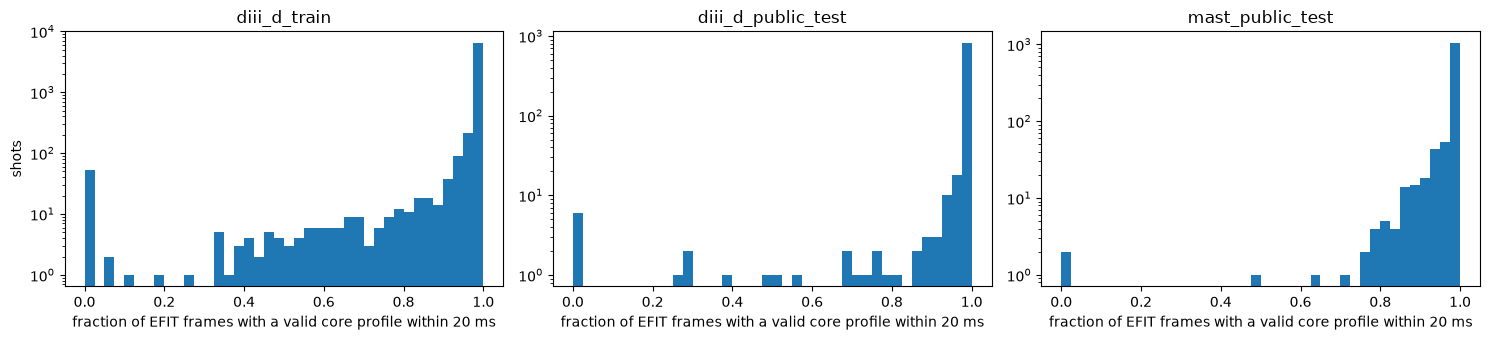

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=False)
for ax, split in zip(axes, SPLITS[:3]):
    sub = qa.loc[qa["split"] == split, COVERAGE].dropna()
    ax.hist(sub, bins=np.linspace(0, 1, 41))
    ax.set_title(split)
    ax.set_xlabel("fraction of EFIT frames with a valid core profile within 20 ms")
    ax.set_yscale("log")
axes[0].set_ylabel("shots")
plt.tight_layout()

worst = qa.sort_values(COVERAGE).head(20)
display(worst[["split", "shot", "time_n_frames", "tsm_core_n_channels", COVERAGE, COVERAGE_ANY,
               "tsm_core_slice_all_missing_frac", "tsm_core_n_times_window"]])

## 3. Frames per shot by split

What the output shows. DIII-D shots are long and MAST shots are short: a median of 241 frames
at 20 ms spacing on DIII-D (about 5 s) against 58 frames at 5 ms spacing on MAST (about
0.3 s). 49 shots have fewer than 10 frames, and gaps between EFIT frames reach 5.2 s (F13).
Lag and rate-of-change features are therefore computed from the continuous input signals by
time, not by frame index.


In [6]:
frames = qa.groupby("split", observed=True)["time_n_frames"]
summary = frames.describe()[["count", "min", "25%", "50%", "75%", "max"]]
summary["total_frames"] = frames.sum()
summary["shots_below_10"] = frames.apply(lambda s: int((s < 10).sum()))
display(summary)
display(qa.loc[qa["time_n_frames"] < 10, ["split", "shot", "time_n_frames", "time_efit_min_ms",
                                           "time_efit_max_ms", "time_efit_dt_median_ms"]])

,count,min,25%,50%,75%,max,total_frames,shots_below_10
split,,,,,,,,
diii_d_train,7041.0,1.0,179.00,241.0,271.00,445.0,1559340.0,42
diii_d_public_test,874.0,3.0,182.25,240.0,272.00,444.0,193359.0,4
mast_public_test,1206.0,5.0,44.00,58.0,71.75,98.0,69075.0,3
mast_samples,3.0,36.0,36.50,37.0,39.50,42.0,115.0,0


,split,shot,time_n_frames,time_efit_min_ms,time_efit_max_ms,time_efit_dt_median_ms
121,diii_d_public_test,2256b2a142,7.0,1620.0,1740.0,20.0
241,diii_d_public_test,410e3b9794,3.0,1740.0,1780.0,20.0
254,diii_d_public_test,443eca0208,9.0,280.0,440.0,20.0
718,diii_d_public_test,cf63340001,7.0,3260.0,3600.0,40.0
925,diii_d_train,01a391fd67,3.0,180.0,2540.0,1180.0
1011,diii_d_train,04c9fd413a,4.0,1620.0,1680.0,20.0
1270,diii_d_train,0d8e17697c,1.0,2780.0,2780.0,NaN
1510,diii_d_train,179019cb31,3.0,120.0,300.0,90.0
1526,diii_d_train,18269a24ec,9.0,280.0,440.0,20.0
1721,diii_d_train,1f1e92dd27,6.0,1620.0,1720.0,20.0


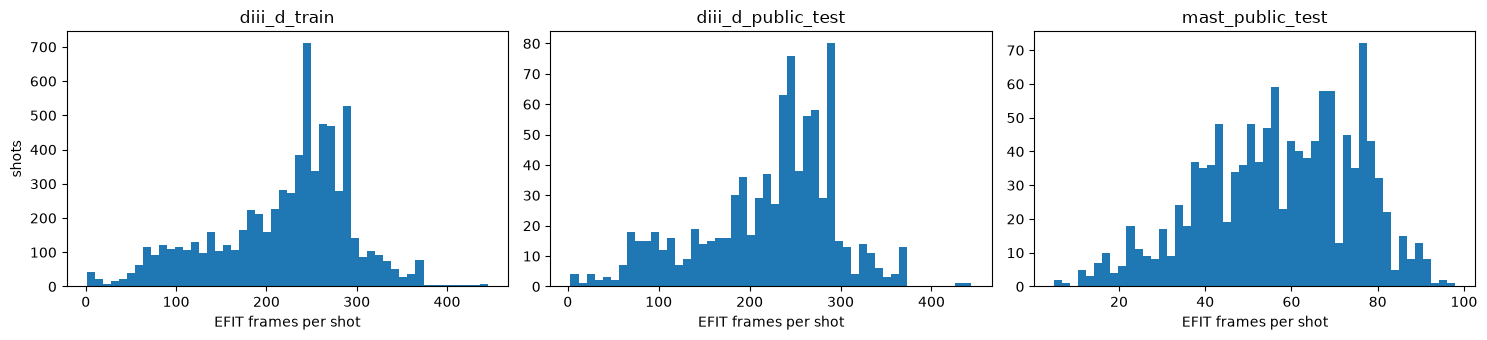

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
for ax, split in zip(axes, SPLITS[:3]):
    sub = qa.loc[qa["split"] == split, "time_n_frames"]
    ax.hist(sub, bins=50)
    ax.set_title(split)
    ax.set_xlabel("EFIT frames per shot")
axes[0].set_ylabel("shots")
plt.tight_layout()

## 4. Flagged shots

Check 0.2 fails a shot when the median |Ip| at the EFIT frames, after the fix, is
below 10 percent of the shot's 99.5th percentile. Check 0.5 flags a shot when the
global psi extremum sits more than one grid cell from the stored axis on any sampled
frame. The per-shot table does not record which frame failed, so the second cell
recomputes the distance on every frame of the opened shot.

What the output shows. The first cells load with `align_ip=False`, the state the organizers'
fix alone produces. In that state the 2 kHz shots had a late Ip axis: Ip at the first EFIT
frame was under 1 percent of the shot's peak on a quarter of them, Ip began to rise at a median
of 188 ms against 15 ms in the 20 kHz group, and more than a quarter had EFIT frames before any
plasma current, while the solenoid swing-down sits at about 1 ms on the coil clock in both
groups (F11). Rule B, now applied by the default loader, shifts each untouched shot so the
rise falls at 14.9 ms: 2,399 shots moved by a median of -173.4 ms (range -332.9 to +55.6 ms),
after which Ip at the first EFIT frame is at least 17 percent of peak on every DIII-D shot and
no frame precedes the rise; the solenoid-anchored rule A agrees within 10 ms on all but 88
shots (F12). The last cell shows that state through the default loader. Separately, on 40
shots the lowest flux value on the map is not at the plasma centre, and on 23 of them it lies
at the grid edge next to a coil; the scorer's interior axis estimate is within one grid cell of
the stored axis on every shot, so the magnetic axis must be located as the interior extremum
(F05).


,split,shot,ip_fix_applied,ip_shift_ms,ip_median_over_p995,ip_median_abs_efit_ka,ip_p995_abs_ka,ip_breakdown_fixed_ms,time_efit_min_ms,time_efit_max_ms
1819,diii_d_train,21f23b2392,False,0.0,0.831512,646.526111,777.530457,300.812927,160.0,440.0


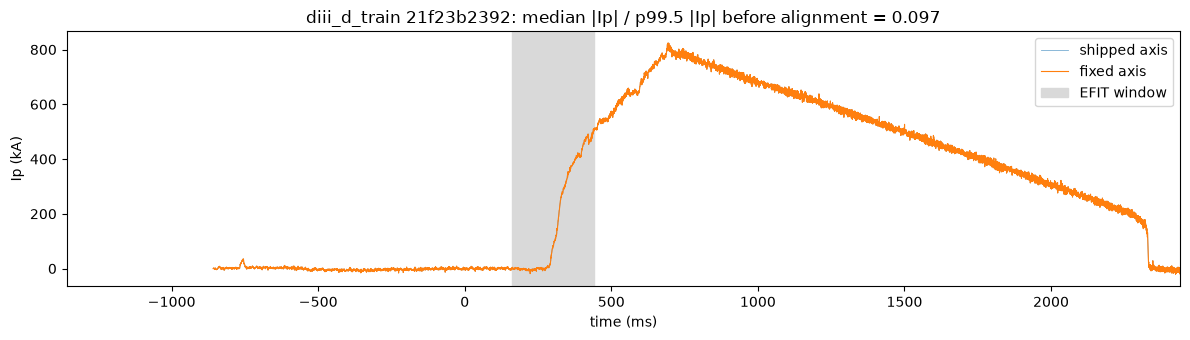

In [8]:
# State before the project's alignment: loads use align_ip=False, so the axis shown is the one
# the organizers' fix alone produces. The per-shot table now reflects the aligned loader, so
# the shot that failed before alignment is named explicitly when no shot fails any more.
failing_ip = qa[(qa["ip_near_zero"] == True) | (qa["ip_covers_efit"] == False)]
if failing_ip.empty:
    failing_ip = qa[(qa["shot"] == "21f23b2392") & (qa["machine"] == "DIII-D")]
display(failing_ip[["split", "shot", "ip_fix_applied", "ip_shift_ms", "ip_median_over_p995",
                    "ip_median_abs_efit_ka", "ip_p995_abs_ka", "ip_breakdown_fixed_ms",
                    "time_efit_min_ms", "time_efit_max_ms"]])

fig, axes = plt.subplots(len(failing_ip), 1, figsize=(12, 3.5 * len(failing_ip)), squeeze=False)
for ax, row in zip(axes[:, 0], failing_ip.itertuples()):
    shot = load_shot(row.path, ["magnetics_plasma_current", "magnetics_plasma_current_times", "efit_times"],
                     align_ip=False)
    ip = shot["magnetics_plasma_current"]
    efit = shot["efit_times"]
    axis = shot["magnetics_plasma_current_times"]
    ratio_before = np.median(np.abs(np.interp(efit, axis, ip))) / np.percentile(np.abs(ip), 99.5)
    ax.plot(shot.fixes["ip_times_shipped"], ip, lw=0.6, alpha=0.6, label="shipped axis")
    ax.plot(shot["magnetics_plasma_current_times"], ip, lw=0.8, label="fixed axis")
    ax.axvspan(efit.min(), efit.max(), color="0.85", label="EFIT window")
    ax.set_xlim(min(efit.min(), shot["magnetics_plasma_current_times"].min()) - 500, efit.max() + 2000)
    ax.set_title(f"{row.split} {row.shot}: median |Ip| / p99.5 |Ip| before alignment = {ratio_before:.3f}")
    ax.set_xlabel("time (ms)")
    ax.set_ylabel("Ip (kA)")
    ax.legend(loc="upper right")
plt.tight_layout()

40 shots flagged by 0.5


,split,shot,psi_axis_within_1cell_frac,psi_axis_cell_dist_max,psi_axis_on_border_frac,time_n_frames,lab_betan_min,lab_li_max
7784,diii_d_train,fb2f142d19,0.4,35.401808,0.6,161.0,0.122435,1.808971
2461,diii_d_train,36bc6cf20f,0.5,34.002255,0.5,148.0,0.107497,1.687954
3837,diii_d_train,695c3c9001,0.5,34.162560,0.5,262.0,0.105501,2.478356
7255,diii_d_train,e6df3967cb,0.7,32.802472,0.3,106.0,0.184787,1.051383
2206,diii_d_train,2e3b352031,0.7,21.910800,0.0,295.0,-0.353547,4.709217
3454,diii_d_train,5ae6a0ed0d,0.7,22.067945,0.0,160.0,0.568045,2.917329
6623,diii_d_train,ced938a97c,0.8,32.203975,0.2,145.0,0.137206,1.521820
5087,diii_d_train,973d6add2d,0.8,31.556565,0.2,92.0,0.129131,1.112583
3841,diii_d_train,698f1cc29c,0.8,32.212399,0.2,82.0,0.112276,1.297845
917,diii_d_train,0153569121,0.9,23.556704,0.0,218.0,0.050093,1.169690


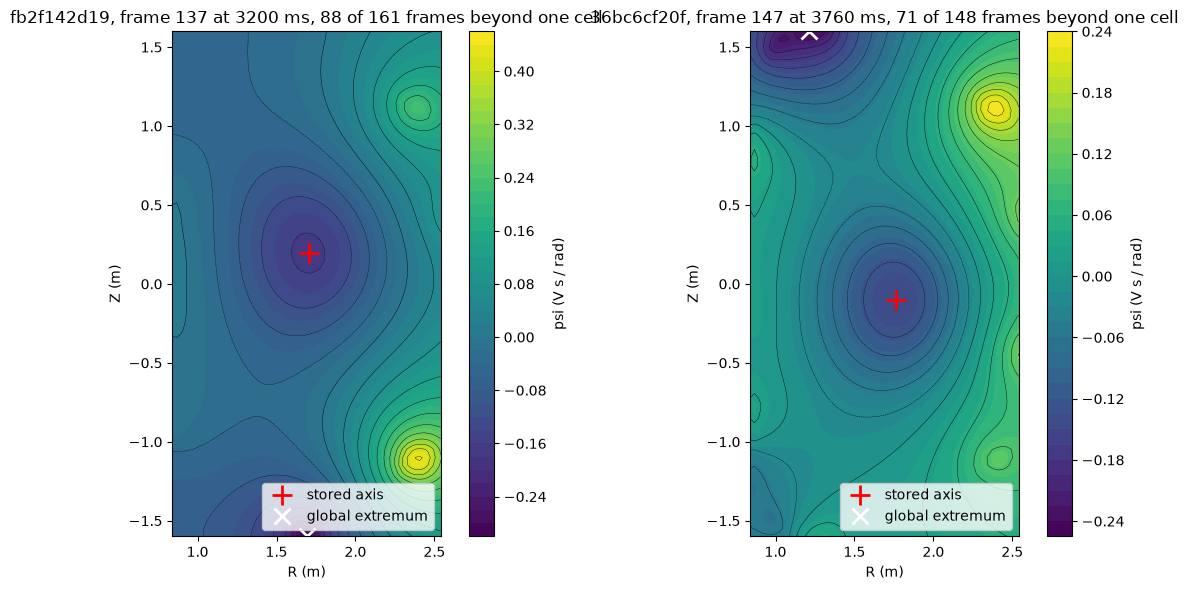

In [9]:
flagged_psi = qa[qa["psi_axis_within_1cell_frac"] < 1].sort_values("psi_axis_within_1cell_frac")
print(len(flagged_psi), "shots flagged by 0.5")
display(flagged_psi[["split", "shot", "psi_axis_within_1cell_frac", "psi_axis_cell_dist_max",
                     "psi_axis_on_border_frac", "time_n_frames", "lab_betan_min", "lab_li_max"]].head(10))

def extremum_cells(shot):
    """Per frame: (iz, ir) of the global extremum under the machine sign and its distance to the axis in cells."""
    psi = shot["efit_psirz"] * shot.machine.axis_sign
    grid_r, grid_z = shot["efit_grid_R"], shot["efit_grid_Z"]
    flat = psi.reshape(psi.shape[0], -1).argmax(axis=1)
    iz, ir = np.unravel_index(flat, psi.shape[1:])
    dist = np.maximum(np.abs(grid_r[ir] - shot["efit_r_axis"]) / np.median(np.diff(grid_r)),
                      np.abs(grid_z[iz] - shot["efit_z_axis"]) / np.median(np.diff(grid_z)))
    return iz, ir, dist

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, row in zip(axes, flagged_psi.head(2).itertuples()):
    shot = load_shot(row.path, ["efit_psirz", "efit_grid_R", "efit_grid_Z", "efit_r_axis", "efit_z_axis", "efit_times"])
    iz, ir, dist = extremum_cells(shot)
    k = int(np.argmax(dist))
    grid_r, grid_z = shot["efit_grid_R"], shot["efit_grid_Z"]
    im = ax.contourf(grid_r, grid_z, shot["efit_psirz"][k], levels=40)
    ax.contour(grid_r, grid_z, shot["efit_psirz"][k], levels=20, colors="k", linewidths=0.3)
    ax.plot(shot["efit_r_axis"][k], shot["efit_z_axis"][k], "r+", ms=14, mew=2, label="stored axis")
    ax.plot(grid_r[ir[k]], grid_z[iz[k]], "wx", ms=12, mew=2, label="global extremum")
    ax.set_aspect("equal")
    ax.set_title(f"{row.shot}, frame {k} at {shot['efit_times'][k]:.0f} ms, "
                 f"{int((dist > 1).sum())} of {dist.size} frames beyond one cell")
    ax.set_xlabel("R (m)")
    ax.set_ylabel("Z (m)")
    ax.legend(loc="lower right")
    plt.colorbar(im, ax=ax, label="psi (V s / rad)")
plt.tight_layout()

1000/7915 shots
2000/7915 shots
3000/7915 shots
4000/7915 shots
5000/7915 shots
6000/7915 shots
7000/7915 shots
ip_first_over_p995


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,0.000,0.000,0.001,0.007,0.256,0.434,0.561,0.953,0.984
20 kHz,0.172,0.219,0.266,0.385,0.460,0.573,0.708,0.976,1.025


ip_breakdown_fixed_ms


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,-40.687,-27.187,67.813,134.313,188.313,271.813,311.313,319.373,347.813
20 kHz,-118.260,7.573,10.101,12.788,14.871,18.384,25.977,49.489,130.731


breakdown_to_first_frame_ms


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,-172.313,-152.813,-148.813,-24.813,38.687,135.187,228.687,1384.687,2931.687
20 kHz,49.269,78.397,84.897,168.928,229.405,283.937,526.193,1765.208,5583.630


,split,shot,magnetics_rate,ip_fix_applied,ip_first_frame_ka,ip_first_over_p995,ip_median_over_p995,ip_breakdown_fixed_ms,time_efit_min_ms,breakdown_to_first_frame_ms
6097,diii_d_train,bbe2e14177,2 kHz,False,-0.001052,8.095730e-07,0.983621,314.312927,160.0,-154.312927
123,diii_d_public_test,2383786859,2 kHz,False,0.003156,2.435318e-06,0.982449,312.812927,160.0,-152.812927
4601,diii_d_train,85d3677967,2 kHz,False,-0.018844,1.871260e-05,0.979854,274.312927,160.0,-114.312927
4813,diii_d_train,8d1575d8c4,2 kHz,False,0.018844,2.511003e-05,0.980210,212.812927,160.0,-52.812927
5447,diii_d_train,a48480daaa,2 kHz,False,0.040843,3.145808e-05,0.982053,312.312927,160.0,-152.312927
2042,diii_d_train,288412efdf,2 kHz,False,0.042948,3.331174e-05,0.935132,236.312927,180.0,-56.312927
5138,diii_d_train,9902d519b0,2 kHz,False,-0.059687,4.003072e-05,0.986560,346.312927,280.0,-66.312927
6222,diii_d_train,c0ec44362c,2 kHz,False,-0.078503,4.424242e-05,0.984318,169.812927,120.0,-49.812927
6929,diii_d_train,daadc74a32,2 kHz,False,0.062843,6.212150e-05,0.979203,273.312927,160.0,-113.312927
7570,diii_d_train,f2f5d78934,2 kHz,False,0.063896,6.375322e-05,0.976352,288.812927,180.0,-108.812927


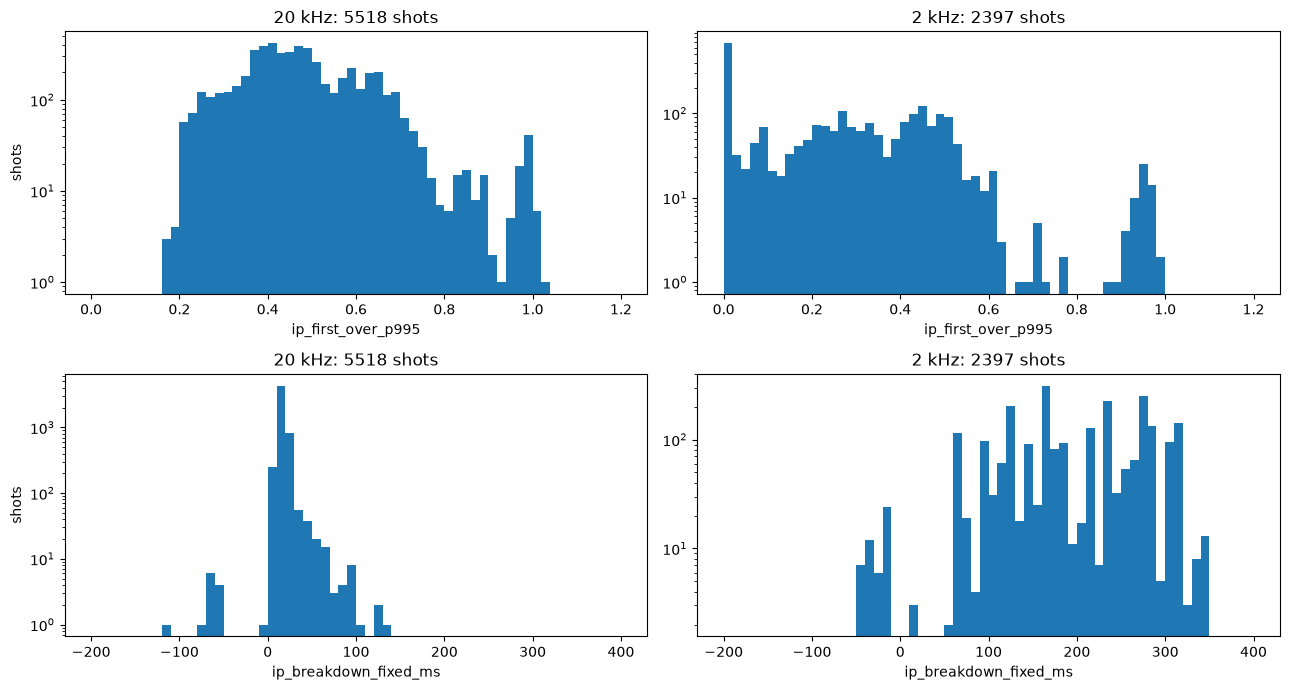

In [10]:
# Ip at the first EFIT frame after the organizers' fix and BEFORE the project's alignment
# (align_ip=False), relative to the shot's 99.5th percentile |Ip|, for every DIII-D shot.
# Reads three columns per shot (the loader adds magnetics_time for the fix); about 8,000
# files, several minutes. Breakdown after the organizers' fix and the recording rate come
# from the QA table (ip_breakdown_fixed_ms is defined before alignment in both QA runs).
d3d_rows = qa[qa["machine"] == "DIII-D"]
IP_COLUMNS = ["magnetics_plasma_current", "magnetics_plasma_current_times", "efit_times"]

records = []
for i, row in enumerate(d3d_rows.itertuples(), start=1):
    shot = load_shot(row.path, IP_COLUMNS, align_ip=False)
    ip = shot["magnetics_plasma_current"].astype(np.float64)
    axis = shot["magnetics_plasma_current_times"]
    order = np.argsort(axis)
    ip_first = float(np.interp(shot["efit_times"][0], axis[order], ip[order]))
    p995 = float(np.percentile(np.abs(ip), 99.5))
    records.append({"split": row.split, "shot": row.shot, "ip_first_frame_ka": ip_first,
                    "ip_first_over_p995": abs(ip_first) / p995 if p995 > 0 else np.nan})
    if i % 1000 == 0:
        print(f"{i}/{len(d3d_rows)} shots")

first_frame = pd.DataFrame(records).merge(
    d3d_rows[["split", "shot", "ip_breakdown_fixed_ms", "ip_fix_applied", "ip_median_over_p995",
              "time_efit_min_ms", "time_magnetics_dt_median_ms"]],
    on=["split", "shot"])
first_frame["magnetics_rate"] = np.where(first_frame["time_magnetics_dt_median_ms"] > 0.1, "2 kHz", "20 kHz")
first_frame["breakdown_to_first_frame_ms"] = first_frame["time_efit_min_ms"] - first_frame["ip_breakdown_fixed_ms"]

QUANTILES = [0.0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]
for column in ["ip_first_over_p995", "ip_breakdown_fixed_ms", "breakdown_to_first_frame_ms"]:
    print(column)
    display(first_frame.groupby("magnetics_rate")[column].quantile(QUANTILES).unstack().round(3))

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax_row, (column, bins) in zip(axes, [("ip_first_over_p995", np.linspace(0, 1.2, 61)),
                                         ("ip_breakdown_fixed_ms", np.linspace(-200, 400, 61))]):
    for ax, rate in zip(ax_row, ["20 kHz", "2 kHz"]):
        sub = first_frame.loc[first_frame["magnetics_rate"] == rate, column].dropna()
        ax.hist(sub.clip(bins[0], bins[-1]), bins=bins)
        ax.set_title(f"{rate}: {len(sub)} shots")
        ax.set_xlabel(column)
        ax.set_yscale("log")
    ax_row[0].set_ylabel("shots")
plt.tight_layout()

display(first_frame.sort_values("ip_first_over_p995").head(20)[
    ["split", "shot", "magnetics_rate", "ip_fix_applied", "ip_first_frame_ka", "ip_first_over_p995",
     "ip_median_over_p995", "ip_breakdown_fixed_ms", "time_efit_min_ms", "breakdown_to_first_frame_ms"]])

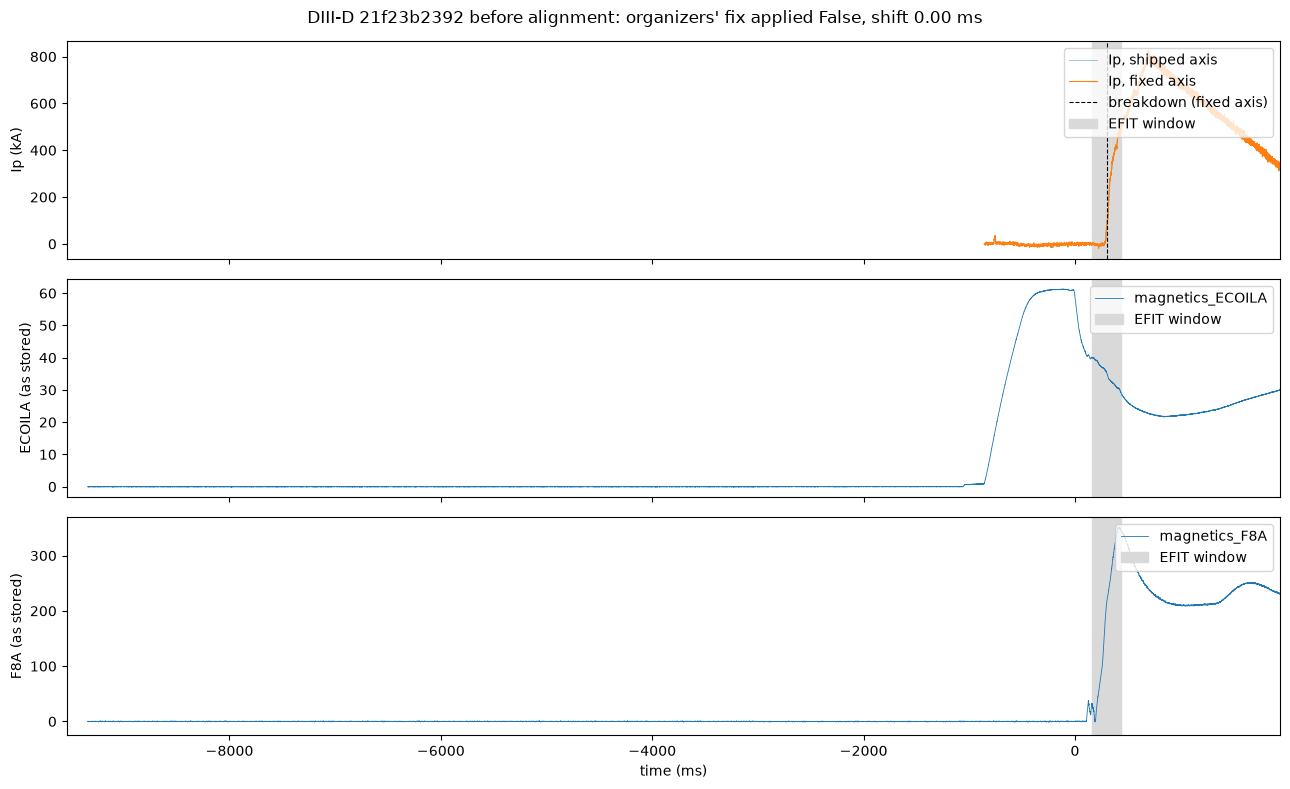

In [11]:
# Shot 21f23b2392: does Ip lag the coil activity. Ip sits on its own (fixed) axis, the coils
# on magnetics_time. The F-coil shown is the one with the largest p99 |value| in this shot.
# Loaded with align_ip=False: the organizers' fix alone, before the project's alignment.
TARGET = "21f23b2392"
row = qa[(qa["shot"] == TARGET) & (qa["machine"] == "DIII-D")].iloc[0]
f_coil_p99 = row.filter(regex=r"^cur_F\d[AB]_p99abs$").astype(float)
f_coil = "magnetics_" + f_coil_p99.idxmax()[len("cur_"):-len("_p99abs")]
shot = load_shot(row["path"], ["magnetics_plasma_current", "magnetics_plasma_current_times",
                              "magnetics_time", "magnetics_ECOILA", f_coil, "efit_times"], align_ip=False)
efit = shot["efit_times"]
t_lo, t_hi = float(shot["magnetics_time"][0]) - 200, float(efit.max()) + 1500

fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)
axes[0].plot(shot.fixes["ip_times_shipped"], shot["magnetics_plasma_current"], lw=0.6, alpha=0.5, label="Ip, shipped axis")
axes[0].plot(shot["magnetics_plasma_current_times"], shot["magnetics_plasma_current"], lw=0.8, label="Ip, fixed axis")
axes[0].axvline(row["ip_breakdown_fixed_ms"], color="k", ls="--", lw=0.8, label="breakdown (fixed axis)")
axes[0].set_ylabel("Ip (kA)")
for ax, column in zip(axes[1:], ["magnetics_ECOILA", f_coil]):
    ax.plot(shot["magnetics_time"], shot[column], lw=0.6, label=column)
    ax.set_ylabel(f"{column[len('magnetics_'):]} (as stored)")
for ax in axes:
    ax.axvspan(efit.min(), efit.max(), color="0.85", label="EFIT window")
    ax.legend(loc="upper right")
axes[-1].set_xlabel("time (ms)")
axes[-1].set_xlim(t_lo, t_hi)
fig.suptitle(f"DIII-D {TARGET} before alignment: organizers' fix applied {row['ip_fix_applied']}, "
             f"shift {row['ip_shift_ms']:.2f} ms")
plt.tight_layout()

1000/7915 shots
2000/7915 shots
3000/7915 shots
4000/7915 shots
5000/7915 shots
6000/7915 shots
7000/7915 shots
shots without an anchor: 2
sol_anchor_ms


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,-68.6,-2.4,-1.4,-0.3,0.8,2.5,3.3,8.8,6530.2
20 kHz,-519.6,-2.4,-1.2,0.3,1.5,2.8,4.1,11.4,5328.6


lag_ms


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,-6314.9,-36.2,68.4,135.7,188.2,268.8,308.0,316.6,345.1
20 kHz,-5316.9,6.4,8.7,11.8,13.8,16.6,22.7,50.5,530.9


ip_breakdown_fixed_ms


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,-40.7,-27.2,67.8,134.3,188.3,271.8,311.3,319.4,347.8
20 kHz,-118.3,7.6,10.1,12.8,14.9,18.4,26.0,49.5,130.7


count   mean    std     min    25%    50%    75%    max
magnetics_rate ip_fix_applied                                                          
2 kHz          False           2395.0  172.3  391.4 -6314.9  135.7  188.2  268.8  345.1
20 kHz         False              2.0  126.8    0.3   126.6  126.7  126.8  126.9  127.0
               True            5516.0   11.8  115.0 -5316.9   11.8   13.8   16.5  530.9

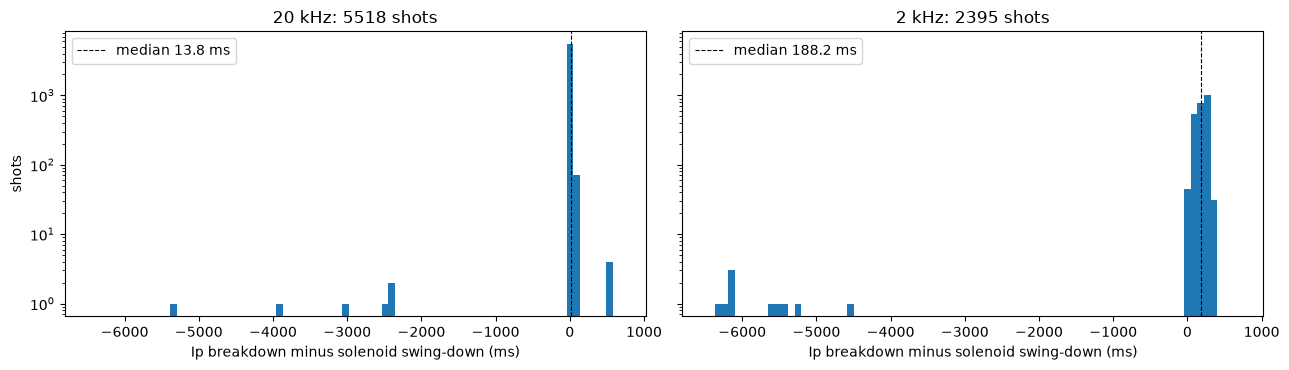

In [12]:
# Candidate A anchor: the solenoid swing-down, the time magnetics_ECOILA leaves its pre-charge
# plateau and starts falling, near 0 ms. For every DIII-D shot.
#
# Definition. ECOILA is oriented so the pre-charge is positive (sign of the value at the first
# crossing of half the record's maximum |ECOILA|), then smoothed with a SMOOTH_MS moving
# average. The plateau is the smoothed maximum. The steepest fall is the sample with the most
# negative slope of the smoothed trace, which is the inductive swing. The anchor is the last
# time at or before the steepest fall where the smoothed trace is still within PLATEAU_TOL of
# the plateau. Lag = Ip breakdown after the organizers' fix (QA table, check 0.2) minus anchor.
# Reads two columns per shot; about 8,000 files, several minutes.
SMOOTH_MS = 5.0
PLATEAU_TOL = 0.05

def moving_average(values, window):
    """Centred moving average over `window` samples, edges padded with the end values."""
    if window <= 1:
        return values
    padded = np.pad(values, (window // 2, window - 1 - window // 2), mode="edge")
    cumsum = np.concatenate([[0.0], np.cumsum(padded)])
    return (cumsum[window:] - cumsum[:-window]) / window

def solenoid_swing_down_ms(times_ms, current, smooth_ms=SMOOTH_MS, tol=PLATEAU_TOL):
    """Time at which the solenoid current leaves its pre-charge plateau. NaN when undefined."""
    t = np.asarray(times_ms, dtype=np.float64)
    c = np.asarray(current, dtype=np.float64)
    finite = np.isfinite(t) & np.isfinite(c)
    t, c = t[finite], c[finite]
    if t.size < 3:
        return np.nan
    peak = np.abs(c).max()
    if peak <= 0:
        return np.nan
    orientation = np.sign(c[int(np.argmax(np.abs(c) > 0.5 * peak))])
    dt = float(np.median(np.diff(t)))
    s = moving_average(orientation * c, max(1, int(round(smooth_ms / dt))))
    plateau = s.max()
    steepest = int(np.argmin(np.gradient(s, t)))
    near_plateau = np.flatnonzero(s[: steepest + 1] >= (1.0 - tol) * plateau)
    if near_plateau.size == 0:
        return np.nan
    return float(t[near_plateau[-1]])

def data_bins(*series, n=80, pad=0.02):
    """Histogram edges spanning every finite value of the given series, so no bar is clipped."""
    values = np.concatenate([np.asarray(pd.Series(s).dropna(), dtype=np.float64) for s in series])
    lo, hi = values.min(), values.max()
    margin = pad * (hi - lo) if hi > lo else 1.0
    return np.linspace(lo - margin, hi + margin, n + 1)

d3d_rows = qa[qa["machine"] == "DIII-D"]
anchor_records = []
for i, row in enumerate(d3d_rows.itertuples(), start=1):
    shot = load_shot(row.path, ["magnetics_time", "magnetics_ECOILA"])
    anchor_records.append({"split": row.split, "shot": row.shot,
                           "sol_anchor_ms": solenoid_swing_down_ms(shot["magnetics_time"], shot["magnetics_ECOILA"])})
    if i % 1000 == 0:
        print(f"{i}/{len(d3d_rows)} shots")

solenoid = pd.DataFrame(anchor_records).merge(
    d3d_rows[["split", "shot", "path", "ip_breakdown_fixed_ms", "ip_fix_applied", "time_efit_min_ms",
              "time_magnetics_dt_median_ms"]], on=["split", "shot"])
solenoid["magnetics_rate"] = np.where(solenoid["time_magnetics_dt_median_ms"] > 0.1, "2 kHz", "20 kHz")
solenoid["lag_ms"] = solenoid["ip_breakdown_fixed_ms"] - solenoid["sol_anchor_ms"]
print("shots without an anchor:", int(solenoid["sol_anchor_ms"].isna().sum()))

QUANTILES = [0.0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1.0]
for column in ["sol_anchor_ms", "lag_ms", "ip_breakdown_fixed_ms"]:
    print(column)
    display(solenoid.groupby("magnetics_rate")[column].quantile(QUANTILES).unstack().round(1))
display(solenoid.groupby(["magnetics_rate", "ip_fix_applied"])["lag_ms"].describe().round(1))

bins = data_bins(solenoid["lag_ms"])
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for ax, rate in zip(axes, ["20 kHz", "2 kHz"]):
    sub = solenoid.loc[solenoid["magnetics_rate"] == rate, "lag_ms"].dropna()
    ax.hist(sub, bins=bins)
    ax.axvline(sub.median(), color="k", ls="--", lw=0.8, label=f"median {sub.median():.1f} ms")
    ax.set_title(f"{rate}: {len(sub)} shots")
    ax.set_xlabel("Ip breakdown minus solenoid swing-down (ms)")
    ax.set_yscale("log")
    ax.legend()
axes[0].set_ylabel("shots")
plt.tight_layout()

20 kHz spread of the anchors


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
A: lag_ms,-5316.9,6.4,8.7,11.8,13.8,16.6,22.7,50.5,530.9
B: ip_breakdown_fixed_ms,-118.3,7.6,10.1,12.8,14.9,18.4,26.0,49.5,130.7


targets: A lag 13.8 ms, B breakdown 14.9 ms
2 kHz shifts (ms)


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
shift_A_ms,-331.4,-302.9,-294.3,-255.0,-174.5,-122.0,-54.7,49.9,6328.6
shift_B_ms,-332.9,-304.5,-296.4,-256.9,-173.4,-119.9,-52.9,42.1,55.6
shift_A_minus_B_ms,-69.8,-3.5,-2.5,-1.4,-0.3,1.3,2.2,7.7,6529.0


share of positive shifts: A 2.2%, B 2.2%
ip_first_over_p995


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
"20 kHz, fixed",0.172,0.219,0.266,0.385,0.460,0.573,0.708,0.976,1.025
"2 kHz, fixed",0.000,0.000,0.001,0.007,0.256,0.434,0.561,0.953,0.984
"2 kHz, A",0.000,0.253,0.298,0.373,0.472,0.546,0.692,0.937,1.013
"2 kHz, B",0.214,0.258,0.300,0.374,0.472,0.547,0.693,0.934,1.025


... (4 outputs left out)

20 worst 2 kHz shots after correction B


,split,shot,ip_fix_applied,ip_breakdown_fixed_ms,sol_anchor_ms,lag_ms,time_efit_min_ms,shift_A_ms,shift_B_ms,ip_first_over_p995,ip_first_over_p995_A,ip_first_over_p995_B,breakdown_to_first_frame_ms_A,breakdown_to_first_frame_ms_B
721,diii_d_train,331a7543a3,False,132.313,-68.631,200.944,120.0,-187.194,-117.442,0.025,0.263,0.214,174.881,105.129
2157,diii_d_train,e0c41c5c44,False,173.313,-0.130,173.443,180.0,-159.693,-158.442,0.120,0.226,0.222,166.380,165.129
492,diii_d_train,1b0eacaae6,False,171.313,-0.132,171.445,180.0,-157.695,-156.442,0.152,0.237,0.229,166.382,165.129
1342,diii_d_train,7ff0a5fa0b,False,100.313,-1.287,101.600,180.0,-87.849,-85.442,0.193,0.235,0.230,167.537,165.129
782,diii_d_train,3a3281aee3,False,170.813,-0.134,170.947,180.0,-157.196,-155.942,0.151,0.232,0.230,166.384,165.129
218,diii_d_public_test,c8ad843a89,False,172.813,-0.108,172.921,180.0,-159.171,-157.942,0.129,0.233,0.230,166.358,165.129
1757,diii_d_train,b2cc708992,False,-27.187,3.447,-30.634,160.0,44.385,42.058,0.244,0.243,0.237,142.803,145.129
1721,diii_d_train,aed73ee2d3,False,171.813,-0.632,172.445,180.0,-158.695,-156.942,0.154,0.237,0.238,166.882,165.129
359,diii_d_train,097956a362,False,223.313,1.770,221.543,220.0,-207.793,-208.442,0.075,0.248,0.240,204.480,205.129
2298,diii_d_train,f2dc32fb9b,False,173.813,-0.132,173.945,180.0,-160.195,-158.942,0.136,0.244,0.241,166.382,165.129


largest |A minus B| differences


,split,shot,ip_fix_applied,ip_breakdown_fixed_ms,sol_anchor_ms,lag_ms,time_efit_min_ms,shift_A_ms,shift_B_ms,ip_first_over_p995,ip_first_over_p995_A,ip_first_over_p995_B,breakdown_to_first_frame_ms_A,breakdown_to_first_frame_ms_B
2100,diii_d_train,d9fa9eac3c,False,215.313,6530.167,-6314.855,160.0,6328.605,-200.442,0.002,0.001,0.568,-6383.918,145.129
1579,diii_d_train,9c6f3f6c5b,False,-31.687,6167.542,-6199.229,160.0,6212.979,46.558,0.430,0.001,0.425,-6021.292,145.129
618,diii_d_train,2816ad1386,False,-27.187,6081.541,-6108.728,160.0,6122.478,42.058,0.427,0.001,0.422,-5935.291,145.129
1422,diii_d_train,888807d624,False,-28.187,6075.542,-6103.729,180.0,6117.479,43.058,0.444,0.001,0.417,-5909.292,165.129
1294,diii_d_train,7ab3d48e6a,False,-40.687,6071.042,-6111.729,160.0,6125.479,55.558,0.445,0.002,0.446,-5924.792,145.129
2231,diii_d_train,ea96cfdd8e,False,-27.187,5612.542,-5639.729,200.0,5653.479,42.058,0.455,0.001,0.430,-5426.292,185.129
339,diii_d_train,065af5741d,False,-40.187,5493.044,-5533.232,160.0,5546.982,55.058,0.439,0.001,0.434,-5346.795,145.129
1423,diii_d_train,888d61f6c8,False,-27.687,5436.542,-5464.230,200.0,5477.980,42.558,0.439,0.004,0.425,-5250.293,185.129
2272,diii_d_train,ef147924bf,False,-13.687,5238.404,-5252.091,200.0,5265.841,28.558,0.458,0.000,0.468,-5052.154,185.129
847,diii_d_train,41b4f53ee7,False,214.313,4765.166,-4550.853,180.0,4564.603,-199.442,0.003,0.000,0.605,-4598.916,165.129


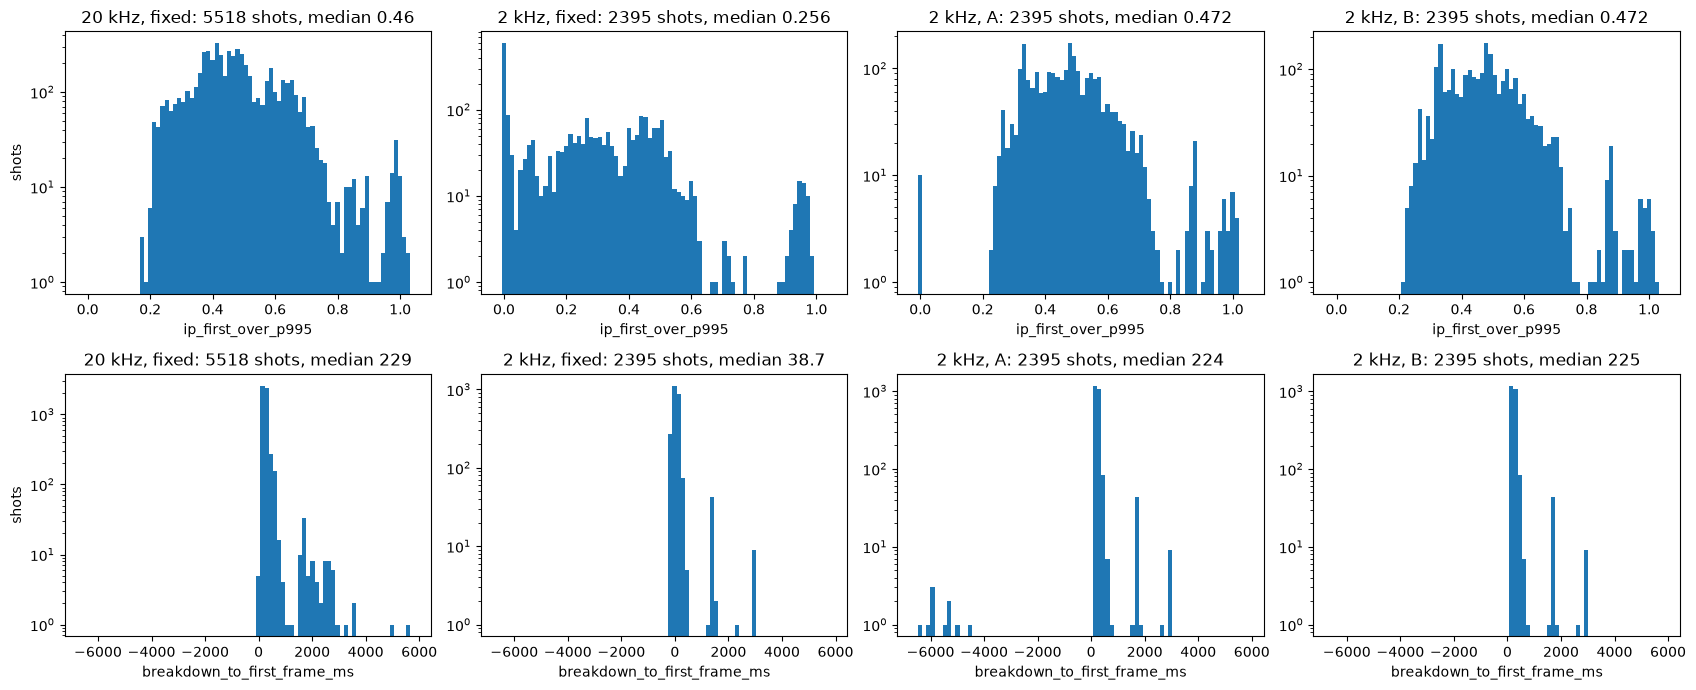

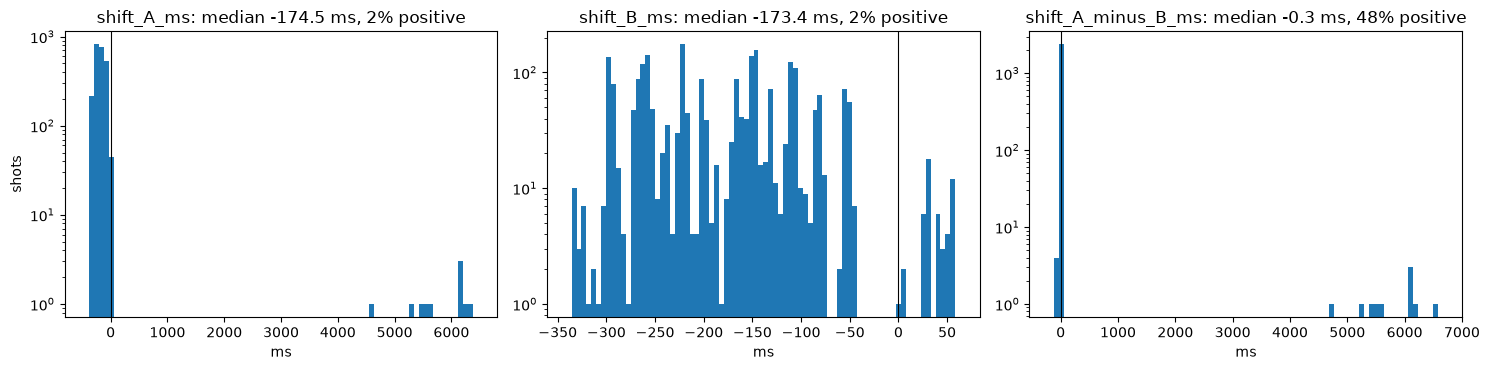

In [13]:
# Two trial corrections of the 2 kHz Ip axes, compared against the 20 kHz group.
#   A: shift so the lag from the swing-down anchor to Ip breakdown equals the 20 kHz median lag.
#   B: shift so the Ip breakdown time equals the 20 kHz median breakdown time.
# Needs `first_frame` (first-frame cell) and `solenoid` (previous cell). Reloads Ip once for
# the 2 kHz shots with align_ip=False, so the shifts start from the organizers' axis. Rule B is
# now implemented in fusion_eq.ip_alignment and applied by the default loader.

def shifted_ip_axis(ip_times_fixed_ms, shift_ms):
    """Returns the fixed Ip time axis moved by shift_ms (positive moves Ip later)."""
    return np.asarray(ip_times_fixed_ms, dtype=np.float64) + shift_ms

def shift_to_lag(lag_ms, target_lag_ms):
    """Candidate A shift: makes the breakdown-to-anchor lag equal to target_lag_ms."""
    return target_lag_ms - lag_ms

def shift_to_breakdown(breakdown_ms, target_breakdown_ms):
    """Candidate B shift: makes the Ip breakdown time equal to target_breakdown_ms."""
    return target_breakdown_ms - breakdown_ms

fast = solenoid[solenoid["magnetics_rate"] == "20 kHz"]
TARGET_LAG_MS = float(fast["lag_ms"].median())
TARGET_BREAKDOWN_MS = float(fast["ip_breakdown_fixed_ms"].median())
print("20 kHz spread of the anchors")
display(pd.DataFrame({"A: lag_ms": fast["lag_ms"].quantile(QUANTILES),
                      "B: ip_breakdown_fixed_ms": fast["ip_breakdown_fixed_ms"].quantile(QUANTILES)}).T.round(1))
print(f"targets: A lag {TARGET_LAG_MS:.1f} ms, B breakdown {TARGET_BREAKDOWN_MS:.1f} ms")

slow = solenoid[(solenoid["magnetics_rate"] == "2 kHz") & solenoid["lag_ms"].notna()].copy()
slow["shift_A_ms"] = shift_to_lag(slow["lag_ms"], TARGET_LAG_MS)
slow["shift_B_ms"] = shift_to_breakdown(slow["ip_breakdown_fixed_ms"], TARGET_BREAKDOWN_MS)
slow["shift_A_minus_B_ms"] = slow["shift_A_ms"] - slow["shift_B_ms"]
print("2 kHz shifts (ms)")
display(slow[["shift_A_ms", "shift_B_ms", "shift_A_minus_B_ms"]].quantile(QUANTILES).T.round(1))
print("share of positive shifts: A {:.1%}, B {:.1%}".format((slow["shift_A_ms"] > 0).mean(), (slow["shift_B_ms"] > 0).mean()))

trial_records = []
for row in slow.itertuples():
    shot = load_shot(row.path, ["magnetics_plasma_current", "magnetics_plasma_current_times", "efit_times"],
                     align_ip=False)
    ip = shot["magnetics_plasma_current"].astype(np.float64)
    p995 = float(np.percentile(np.abs(ip), 99.5))
    record = {"split": row.split, "shot": row.shot}
    for tag, shift in (("A", row.shift_A_ms), ("B", row.shift_B_ms)):
        axis = shifted_ip_axis(shot["magnetics_plasma_current_times"], shift)
        order = np.argsort(axis)
        ip_first = float(np.interp(shot["efit_times"][0], axis[order], ip[order]))
        record[f"ip_first_over_p995_{tag}"] = abs(ip_first) / p995 if p995 > 0 else np.nan
        record[f"breakdown_to_first_frame_ms_{tag}"] = row.time_efit_min_ms - (row.ip_breakdown_fixed_ms + shift)
    trial_records.append(record)
trial = slow.merge(pd.DataFrame(trial_records), on=["split", "shot"]).merge(
    first_frame[["split", "shot", "ip_first_over_p995", "breakdown_to_first_frame_ms"]], on=["split", "shot"])
reference = first_frame[first_frame["magnetics_rate"] == "20 kHz"]

columns = {}
for metric in ["ip_first_over_p995", "breakdown_to_first_frame_ms"]:
    columns[metric] = [("20 kHz, fixed", reference[metric]), ("2 kHz, fixed", trial[metric]),
                       ("2 kHz, A", trial[f"{metric}_A"]), ("2 kHz, B", trial[f"{metric}_B"])]
    print(metric)
    display(pd.DataFrame({name: s.quantile(QUANTILES) for name, s in columns[metric]}).T.round(3))

fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax_row, (metric, items) in zip(axes, columns.items()):
    bins = data_bins(*[s for _, s in items])
    for ax, (name, values) in zip(ax_row, items):
        values = values.dropna()
        ax.hist(values, bins=bins)
        ax.set_title(f"{name}: {len(values)} shots, median {values.median():.3g}")
        ax.set_xlabel(metric)
        ax.set_yscale("log")
    ax_row[0].set_ylabel("shots")
plt.tight_layout()

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, column in zip(axes, ["shift_A_ms", "shift_B_ms", "shift_A_minus_B_ms"]):
    values = slow[column].dropna()
    ax.hist(values, bins=data_bins(values))
    ax.axvline(0, color="k", lw=0.8)
    ax.set_title(f"{column}: median {values.median():.1f} ms, {(values > 0).mean():.0%} positive")
    ax.set_xlabel("ms")
    ax.set_yscale("log")
axes[0].set_ylabel("shots")
plt.tight_layout()

show = ["split", "shot", "ip_fix_applied", "ip_breakdown_fixed_ms", "sol_anchor_ms", "lag_ms", "time_efit_min_ms",
        "shift_A_ms", "shift_B_ms", "ip_first_over_p995", "ip_first_over_p995_A", "ip_first_over_p995_B",
        "breakdown_to_first_frame_ms_A", "breakdown_to_first_frame_ms_B"]
for tag in ("A", "B"):
    print(f"20 worst 2 kHz shots after correction {tag}")
    display(trial.sort_values(f"ip_first_over_p995_{tag}").head(20)[show].round(3))
print("largest |A minus B| differences")
display(trial.reindex(trial["shift_A_minus_B_ms"].abs().sort_values(ascending=False).index).head(20)[show].round(3))

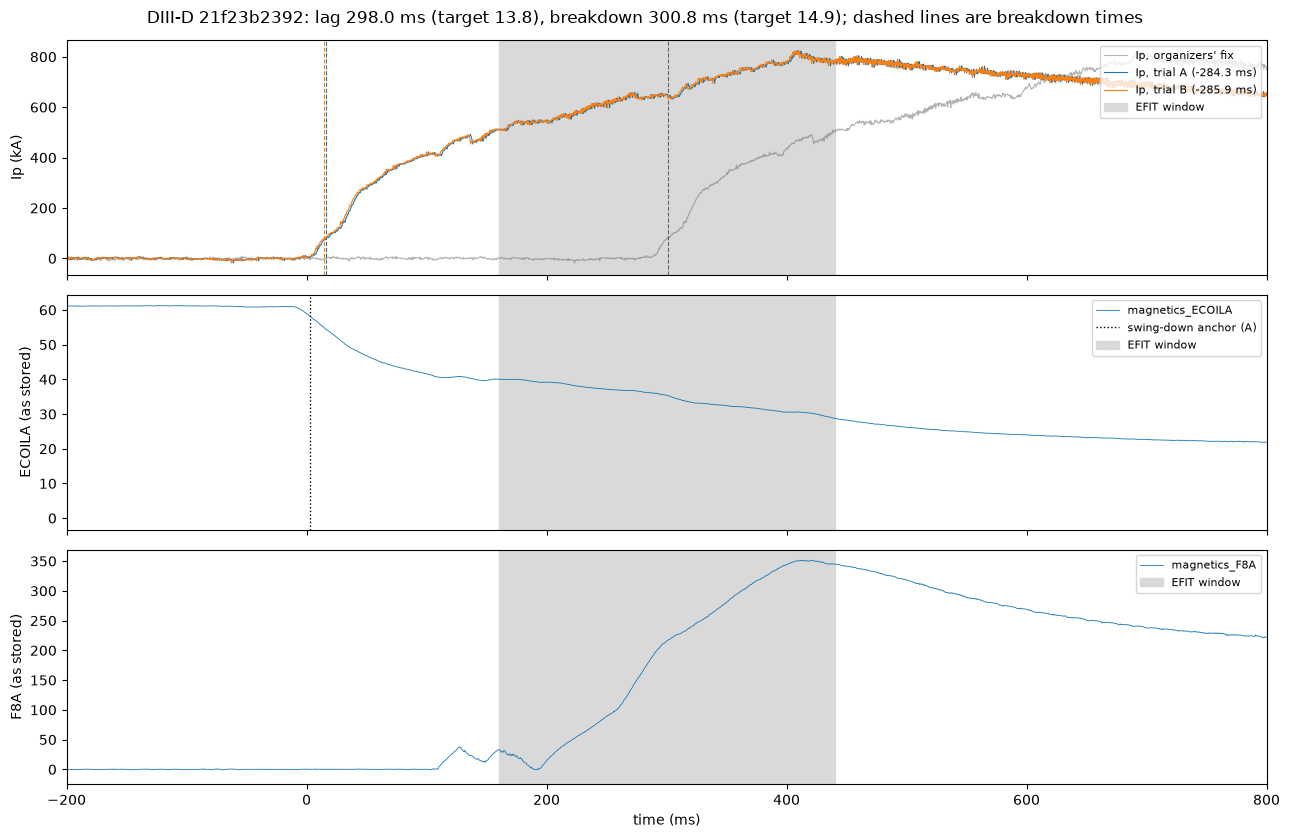

In [14]:
# Shot 21f23b2392 under both trial corrections, -200 to 800 ms.
TARGET = "21f23b2392"
row = qa[(qa["shot"] == TARGET) & (qa["machine"] == "DIII-D")].iloc[0]
trial_row = trial[trial["shot"] == TARGET].iloc[0]
f_coil_p99 = row.filter(regex=r"^cur_F\d[AB]_p99abs$").astype(float)
f_coil = "magnetics_" + f_coil_p99.idxmax()[len("cur_"):-len("_p99abs")]
shot = load_shot(row["path"], ["magnetics_plasma_current", "magnetics_plasma_current_times",
                              "magnetics_time", "magnetics_ECOILA", f_coil, "efit_times"], align_ip=False)
efit = shot["efit_times"]
ip = shot["magnetics_plasma_current"]
axis_fixed = shot["magnetics_plasma_current_times"]
breakdown = row["ip_breakdown_fixed_ms"]

fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True)
axes[0].plot(axis_fixed, ip, lw=0.8, alpha=0.5, color="0.4", label="Ip, organizers' fix")
axes[0].axvline(breakdown, color="0.4", ls="--", lw=0.8)
for color, tag in (("C0", "A"), ("C1", "B")):
    shift = trial_row[f"shift_{tag}_ms"]
    axes[0].plot(shifted_ip_axis(axis_fixed, shift), ip, lw=0.8, color=color, label=f"Ip, trial {tag} ({shift:+.1f} ms)")
    axes[0].axvline(breakdown + shift, color=color, ls="--", lw=0.8)
axes[0].set_ylabel("Ip (kA)")
for ax, column in zip(axes[1:], ["magnetics_ECOILA", f_coil]):
    ax.plot(shot["magnetics_time"], shot[column], lw=0.6, label=column)
    ax.set_ylabel(f"{column[len('magnetics_'):]} (as stored)")
axes[1].axvline(trial_row["sol_anchor_ms"], color="k", ls=":", lw=1.0, label="swing-down anchor (A)")
for ax in axes:
    ax.axvspan(efit.min(), efit.max(), color="0.85", label="EFIT window")
    ax.legend(loc="upper right", fontsize=8)
axes[-1].set_xlabel("time (ms)")
axes[-1].set_xlim(-200, 800)
fig.suptitle(f"DIII-D {TARGET}: lag {trial_row['lag_ms']:.1f} ms (target {TARGET_LAG_MS:.1f}), "
             f"breakdown {breakdown:.1f} ms (target {TARGET_BREAKDOWN_MS:.1f}); dashed lines are breakdown times")
plt.tight_layout()

1000/7915 shots
2000/7915 shots
3000/7915 shots
4000/7915 shots
5000/7915 shots
6000/7915 shots
7000/7915 shots
alignment applied: {'2 kHz': 1.0, '20 kHz': 0.0}
shift (ms) on aligned shots:


0.00   -332.9
0.01   -304.4
0.05   -296.4
0.25   -256.9
0.50   -173.4
0.75   -119.2
0.95    -52.9
0.99     42.1
1.00     55.6
Name: alignment_shift_ms, dtype: float64

ip_first_over_p995_loader


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,0.214,0.258,0.301,0.374,0.472,0.547,0.693,0.934,1.027
20 kHz,0.172,0.219,0.266,0.385,0.460,0.573,0.708,0.976,1.025


breakdown_to_first_frame_ms_loader


,0.00,0.01,0.05,0.25,0.50,0.75,0.95,0.99,1.00
magnetics_rate,,,,,,,,,
2 kHz,105.100,125.100,145.100,165.100,225.100,285.100,405.100,1645.100,3005.10
20 kHz,49.269,78.397,84.897,168.928,229.625,283.938,526.193,1765.208,5583.63


max |loader minus QA table|: ratio 0.00e+00, gap (ms) 0.00e+00


,split,shot,alignment_applied,alignment_shift_ms,ip_first_over_p995_loader,breakdown_to_first_frame_ms_loader,time_magnetics_dt_median_ms,ip_first_over_p995,ip_breakdown_to_first_frame_ms,magnetics_rate
7766,diii_d_train,faba7a5d3c,False,0.0,0.171602,69.519958,0.049927,0.171602,69.519958,20 kHz
1038,diii_d_train,05d575ac7e,False,0.0,0.173232,99.691101,0.049927,0.173232,99.691101,20 kHz
6102,diii_d_train,bc0f6ecd42,False,0.0,0.173540,151.266052,0.049927,0.173540,151.266052,20 kHz
5465,diii_d_train,a503b26d58,False,0.0,0.190808,59.193298,0.049927,0.190808,59.193298,20 kHz
1712,diii_d_train,1ef9a2a63a,False,0.0,0.192783,72.628357,0.049927,0.192783,72.628357,20 kHz
7713,diii_d_train,f898482e57,False,0.0,0.195102,160.927185,0.049927,0.195102,160.927185,20 kHz
647,diii_d_public_test,bad84fd11e,False,0.0,0.195149,160.927917,0.049927,0.195149,160.927917,20 kHz
6006,diii_d_train,b8e064051c,False,0.0,0.200716,177.764587,0.049927,0.200716,177.764587,20 kHz
3939,diii_d_train,6d43932677,False,0.0,0.201641,153.902771,0.049927,0.201641,153.902771,20 kHz
4400,diii_d_train,7ec4cf8c9a,False,0.0,0.201835,153.902771,0.049927,0.201835,153.902771,20 kHz


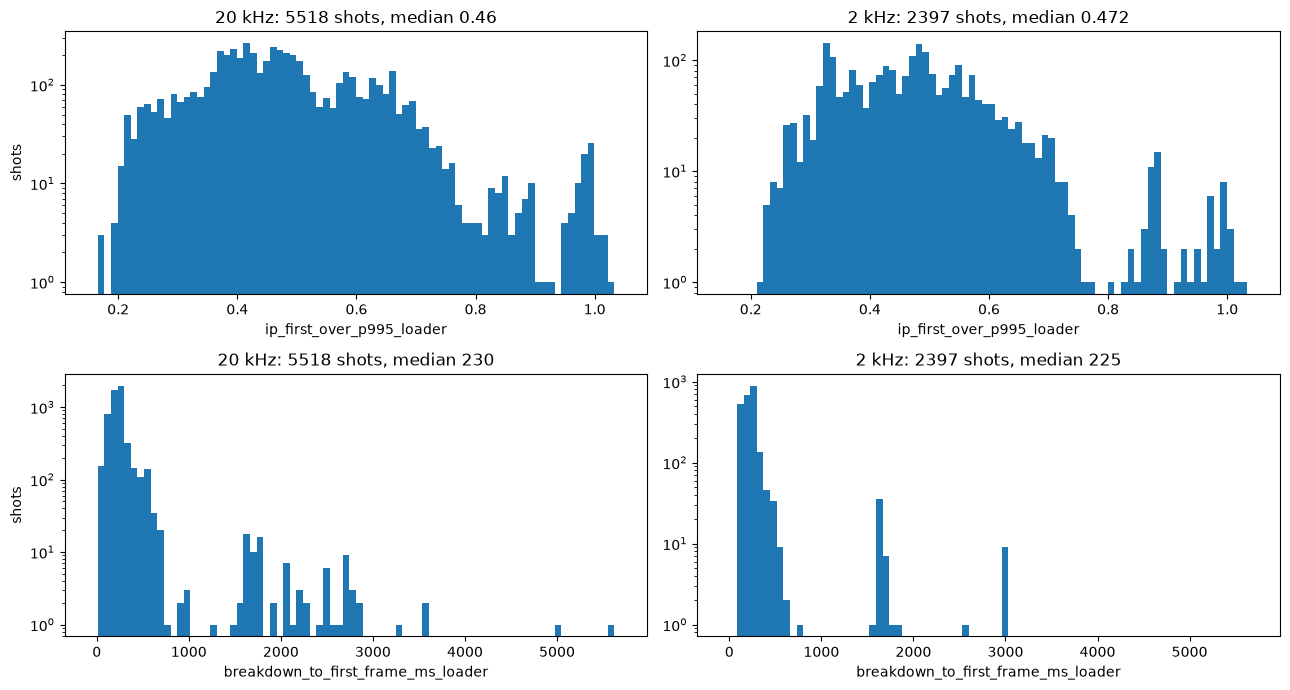

In [15]:
# State through the default loader (rule B alignment on): |Ip| at the first EFIT frame over the
# shot's 99.5th percentile, and the gap from breakdown to the first EFIT frame, by recording
# rate. Breakdown after alignment is taken from Shot.fixes. Needs `d3d_rows`, `IP_COLUMNS` and
# `QUANTILES` (first-frame cell) and `data_bins` (anchor cell). About 8,000 files, several minutes.
aligned_records = []
for i, row in enumerate(d3d_rows.itertuples(), start=1):
    shot = load_shot(row.path, IP_COLUMNS)
    ip = shot["magnetics_plasma_current"].astype(np.float64)
    axis = shot["magnetics_plasma_current_times"]
    order = np.argsort(axis)
    ip_first = float(np.interp(shot["efit_times"][0], axis[order], ip[order]))
    p995 = float(np.percentile(np.abs(ip), 99.5))
    aligned_records.append({
        "split": row.split, "shot": row.shot,
        "alignment_applied": bool(shot.fixes.get("ip_alignment_applied", False)),
        "alignment_shift_ms": float(shot.fixes.get("ip_alignment_shift_ms", 0.0)),
        "ip_first_over_p995_loader": abs(ip_first) / p995 if p995 > 0 else np.nan,
        "breakdown_to_first_frame_ms_loader": float(shot["efit_times"][0]) - shot.fixes["ip_breakdown_after_ms"],
    })
    if i % 1000 == 0:
        print(f"{i}/{len(d3d_rows)} shots")

aligned = pd.DataFrame(aligned_records).merge(
    d3d_rows[["split", "shot", "time_magnetics_dt_median_ms", "ip_first_over_p995", "ip_breakdown_to_first_frame_ms"]],
    on=["split", "shot"])
aligned["magnetics_rate"] = np.where(aligned["time_magnetics_dt_median_ms"] > 0.1, "2 kHz", "20 kHz")
print("alignment applied:", aligned.groupby("magnetics_rate")["alignment_applied"].mean().round(3).to_dict())
print("shift (ms) on aligned shots:")
display(aligned.loc[aligned["alignment_applied"], "alignment_shift_ms"].quantile(QUANTILES).round(1))

for column in ["ip_first_over_p995_loader", "breakdown_to_first_frame_ms_loader"]:
    print(column)
    display(aligned.groupby("magnetics_rate")[column].quantile(QUANTILES).unstack().round(3))

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax_row, column in zip(axes, ["ip_first_over_p995_loader", "breakdown_to_first_frame_ms_loader"]):
    bins = data_bins(aligned[column])
    for ax, rate in zip(ax_row, ["20 kHz", "2 kHz"]):
        sub = aligned.loc[aligned["magnetics_rate"] == rate, column].dropna()
        ax.hist(sub, bins=bins)
        ax.set_title(f"{rate}: {len(sub)} shots, median {sub.median():.3g}")
        ax.set_xlabel(column)
        ax.set_yscale("log")
    ax_row[0].set_ylabel("shots")
plt.tight_layout()

# Cross-check against the columns check 0.2 wrote with the same loader.
print("max |loader minus QA table|: ratio",
      f"{(aligned['ip_first_over_p995_loader'] - aligned['ip_first_over_p995']).abs().max():.2e}, gap (ms)",
      f"{(aligned['breakdown_to_first_frame_ms_loader'] - aligned['ip_breakdown_to_first_frame_ms']).abs().max():.2e}")
display(aligned.sort_values("ip_first_over_p995_loader").head(10))

## 5. Extreme betaN, q95 and li; betaN sign against Ip and bcoil

Per-shot extremes come from the label metrics of check 0.11. Signs of Ip and bcoil
are taken from the signed min and max inside the EFIT window (check 0.4), so they are
per shot, not per frame.

What the output shows. Extreme label values are of four kinds: physical extremes (q95 up to
about 24 at low current, betaN up to about 4.8), failed reconstructions (betaN down to -14.5 on
the shots where stored li reaches 8 to 21), placeholder zeros (betaN and li exactly 0 on some
frames), and two whole shots (`5df1630aa7`, `955c35c962`) with q95 below about 1 and betaN of
14 to 17 (F21). Negative betaN is not a sign convention: 339 training shots contain some
negative frames, none is negative throughout, and it occurs for every combination of Ip and
field direction, so betaN and q95 are treated as positive quantities (F22). Failed and
placeholder frames are to be dropped or down-weighted in training.


In [16]:
labelled = qa[qa["lab_all_finite"].notna()]
EXTREMES = [("lab_betan_min", True), ("lab_betan_max", False), ("lab_q95_min", True), ("lab_q95_max", False),
            ("lab_li_min", True), ("lab_li_max", False)]
show = ["split", "shot", "machine", "time_n_frames", "lab_betan_min", "lab_betan_max", "lab_q95_min",
        "lab_q95_max", "lab_li_min", "lab_li_max"]
for column, ascending in EXTREMES:
    print(f"{column}, {'lowest' if ascending else 'highest'} 5 per machine")
    display(labelled.sort_values(column, ascending=ascending).groupby("machine").head(5)[show])

lab_betan_min, lowest 5 per machine


,split,shot,machine,time_n_frames,lab_betan_min,lab_betan_max,lab_q95_min,lab_q95_max,lab_li_min,lab_li_max
2126,diii_d_train,2b9b50b9b4,DIII-D,297.0,-14.531927,3.689250,1.740220,8.145966,0.732201,20.834949
7077,diii_d_train,e06e2c3b87,DIII-D,299.0,-12.482215,3.574570,1.327671,8.168000,0.721141,14.268064
6228,diii_d_train,c1074feba1,DIII-D,298.0,-7.649787,3.093322,2.769532,8.184588,0.724313,16.763567
7416,diii_d_train,ece59789d7,DIII-D,298.0,-6.481922,3.392867,3.898399,8.070203,0.738721,14.485302
1139,diii_d_train,093271317c,DIII-D,296.0,-3.398529,3.942588,5.303929,8.140631,0.692742,7.842335
9122,mast_samples,28350,MAST,42.0,0.501417,1.322318,5.579837,11.774293,0.611419,1.657821
9123,mast_samples,28351,MAST,37.0,0.508401,1.308773,5.618466,11.913728,0.611498,1.658529
9121,mast_samples,28348,MAST,36.0,0.551242,1.337195,5.626055,11.495637,0.619583,1.671644


lab_betan_max, highest 5 per machine


,split,shot,machine,time_n_frames,lab_betan_min,lab_betan_max,lab_q95_min,lab_q95_max,lab_li_min,lab_li_max
3534,diii_d_train,5df1630aa7,DIII-D,316.0,0.968633,16.654774,0.170922,1.012879,0.832470,1.568570
5037,diii_d_train,955c35c962,DIII-D,292.0,0.819396,14.151655,0.165976,0.945519,0.732420,1.656807
6808,diii_d_train,d597b8ec22,DIII-D,237.0,0.354870,4.783972,3.431333,6.012207,0.753835,1.362355
3006,diii_d_train,4a4670f0d4,DIII-D,71.0,0.061195,4.659220,4.697416,12.772902,0.718740,1.613816
7330,diii_d_train,e9b30256ee,DIII-D,301.0,0.189745,4.608958,5.422017,11.099469,0.638124,2.121960
9121,mast_samples,28348,MAST,36.0,0.551242,1.337195,5.626055,11.495637,0.619583,1.671644
9122,mast_samples,28350,MAST,42.0,0.501417,1.322318,5.579837,11.774293,0.611419,1.657821
9123,mast_samples,28351,MAST,37.0,0.508401,1.308773,5.618466,11.913728,0.611498,1.658529


lab_q95_min, lowest 5 per machine


,split,shot,machine,time_n_frames,lab_betan_min,lab_betan_max,lab_q95_min,lab_q95_max,lab_li_min,lab_li_max
5037,diii_d_train,955c35c962,DIII-D,292.0,0.819396,14.151655,0.165976,0.945519,0.732420,1.656807
3534,diii_d_train,5df1630aa7,DIII-D,316.0,0.968633,16.654774,0.170922,1.012879,0.832470,1.568570
7077,diii_d_train,e06e2c3b87,DIII-D,299.0,-12.482215,3.574570,1.327671,8.168000,0.721141,14.268064
5176,diii_d_train,9a7968e458,DIII-D,249.0,0.000000,2.237029,1.449452,16.864967,0.000000,3.407431
2126,diii_d_train,2b9b50b9b4,DIII-D,297.0,-14.531927,3.689250,1.740220,8.145966,0.732201,20.834949
9122,mast_samples,28350,MAST,42.0,0.501417,1.322318,5.579837,11.774293,0.611419,1.657821
9123,mast_samples,28351,MAST,37.0,0.508401,1.308773,5.618466,11.913728,0.611498,1.658529
9121,mast_samples,28348,MAST,36.0,0.551242,1.337195,5.626055,11.495637,0.619583,1.671644


... (2 outputs left out)

lab_li_min, lowest 5 per machine


,split,shot,machine,time_n_frames,lab_betan_min,lab_betan_max,lab_q95_min,lab_q95_max,lab_li_min,lab_li_max
904,diii_d_train,0100c25bd9,DIII-D,260.0,0.000000,2.350910,3.765892,13.268399,0.000000,2.690579
5176,diii_d_train,9a7968e458,DIII-D,249.0,0.000000,2.237029,1.449452,16.864967,0.000000,3.407431
5449,diii_d_train,a495250f5b,DIII-D,329.0,-0.071838,3.408899,4.682870,12.360465,0.396425,3.827603
6132,diii_d_train,bda1f9217d,DIII-D,66.0,0.034888,0.223720,6.787358,13.376269,0.414838,1.726785
2871,diii_d_train,45d2869d56,DIII-D,238.0,0.051664,0.315459,3.740796,11.050739,0.424796,1.677684
9122,mast_samples,28350,MAST,42.0,0.501417,1.322318,5.579837,11.774293,0.611419,1.657821
9123,mast_samples,28351,MAST,37.0,0.508401,1.308773,5.618466,11.913728,0.611498,1.658529
9121,mast_samples,28348,MAST,36.0,0.551242,1.337195,5.626055,11.495637,0.619583,1.671644


lab_li_max, highest 5 per machine


,split,shot,machine,time_n_frames,lab_betan_min,lab_betan_max,lab_q95_min,lab_q95_max,lab_li_min,lab_li_max
2126,diii_d_train,2b9b50b9b4,DIII-D,297.0,-14.531927,3.689250,1.740220,8.145966,0.732201,20.834949
6228,diii_d_train,c1074feba1,DIII-D,298.0,-7.649787,3.093322,2.769532,8.184588,0.724313,16.763567
7416,diii_d_train,ece59789d7,DIII-D,298.0,-6.481922,3.392867,3.898399,8.070203,0.738721,14.485302
6911,diii_d_train,d9ab71bb50,DIII-D,240.0,-3.102586,1.909573,4.156446,13.706193,0.882902,14.274253
7077,diii_d_train,e06e2c3b87,DIII-D,299.0,-12.482215,3.574570,1.327671,8.168000,0.721141,14.268064
9121,mast_samples,28348,MAST,36.0,0.551242,1.337195,5.626055,11.495637,0.619583,1.671644
9123,mast_samples,28351,MAST,37.0,0.508401,1.308773,5.618466,11.913728,0.611498,1.658529
9122,mast_samples,28350,MAST,42.0,0.501417,1.322318,5.579837,11.774293,0.611419,1.657821


In [17]:
def sign_class(vmin, vmax):
    """'positive', 'negative' or 'mixed' from a per-shot signed min and max."""
    return np.select([vmin >= 0, vmax <= 0], ["positive", "negative"], default="mixed")

signs = labelled.assign(
    betan_sign=sign_class(labelled["lab_betan_min"], labelled["lab_betan_max"]),
    ip_sign=sign_class(labelled["cur_plasma_current_min"], labelled["cur_plasma_current_max"]),
    bcoil_sign=sign_class(labelled["cur_bcoil_min"], labelled["cur_bcoil_max"]),
)
display(pd.crosstab(signs["split"], signs["betan_sign"]))
display(pd.crosstab([signs["ip_sign"], signs["bcoil_sign"]], signs["betan_sign"], margins=True))
negative = signs[signs["betan_sign"] != "positive"]
display(negative[["split", "shot", "betan_sign", "ip_sign", "bcoil_sign", "lab_betan_min", "lab_betan_max",
                  "lab_q95_min", "lab_li_min", "time_n_frames"]].head(20))

betan_sign,mixed,positive
split,,
diii_d_train,339,6702
mast_samples,0,3


betan_sign           mixed  positive   All
ip_sign  bcoil_sign                       
mixed    mixed           0        14    14
         negative        0         3     3
         positive        0         1     1
negative negative        0       394   394
         positive        3       206   209
positive mixed           0         3     3
         negative      225      3424  3649
         positive      111      2660  2771
All                    339      6705  7044

,split,shot,betan_sign,ip_sign,bcoil_sign,lab_betan_min,lab_betan_max,lab_q95_min,lab_li_min,time_n_frames
892,diii_d_train,0092a9ade0,mixed,positive,negative,-0.193292,0.258749,5.234879,0.995427,75.0
925,diii_d_train,01a391fd67,mixed,positive,positive,-1.374942,0.199145,12.149085,2.875700,3.0
942,diii_d_train,02758af4cf,mixed,positive,negative,-0.005635,0.257540,3.217395,1.079536,84.0
949,diii_d_train,02c92316b3,mixed,positive,negative,-0.438387,0.746893,4.201885,0.669571,253.0
971,diii_d_train,037c2db689,mixed,positive,negative,-0.003611,3.135574,4.218698,0.550233,288.0
976,diii_d_train,03d10f9449,mixed,positive,positive,-0.373432,2.878252,5.415915,0.585319,280.0
993,diii_d_train,043557db5d,mixed,positive,negative,-0.666720,1.415996,4.049408,1.054531,310.0
1019,diii_d_train,050e6945dc,mixed,positive,negative,-0.398501,0.696057,3.885489,0.542837,154.0
1037,diii_d_train,05d137f577,mixed,positive,negative,-0.044638,2.524507,3.116031,0.920014,254.0
1038,diii_d_train,05d575ac7e,mixed,positive,negative,-0.326708,1.423821,3.824563,0.901565,286.0


## 6. Shots by Ip direction

What the output shows. DIII-D runs the plasma current and the toroidal field in both
directions, MAST runs one. After the alignment, Ip is positive on about 91 percent of DIII-D
shots and negative on about 9 percent (training 6,420 positive, 603 negative; test 798 and
76), and the toroidal field current is negative on 57 percent and positive on 42 percent
(F14). The mixed group fell from 616 shots to 18 once the late Ip axis was corrected, which
resolves open item 2. The MAST plasma current lies inside the DIII-D range, so Ip needs no
extrapolation on MAST (F15).


In [18]:
ip_sign = pd.Series(sign_class(qa["cur_plasma_current_min"], qa["cur_plasma_current_max"]), index=qa.index)
display(pd.crosstab(qa["split"], ip_sign, margins=True))
display(qa.assign(ip_sign=ip_sign).groupby(["machine", "ip_sign"], observed=True)[
    ["cur_plasma_current_min", "cur_plasma_current_max", "cur_plasma_current_p99abs"]].describe().round(1))

col_0,mixed,negative,positive,All
split,,,,
diii_d_train,18,603,6420,7041
diii_d_public_test,0,76,798,874
mast_public_test,0,0,1206,1206
mast_samples,0,0,3,3
All,18,679,8427,9124


cur_plasma_current_min                                                        cur_plasma_current_max                                         \
                                  count    mean    std     min     25%     50%     75%     max                  count    mean    std     min     25%     50%   
machine ip_sign                                                                                                                                                
DIII-D  mixed                       4.0    -7.4    7.3   -18.2    -8.2    -4.6    -3.8    -2.2                    4.0  1353.6   86.2  1245.6  1303.4  1372.1   
        negative                  679.0 -1119.3  183.3 -1704.3 -1141.5 -1121.8 -1030.7  -526.7                  679.0  -428.9   91.6  -793.0  -482.8  -449.4   
        positive                 7218.0   460.6  144.2     7.1   390.5   475.8   538.8  1118.0                 7218.0  1150.6  300.6   231.5   933.2  1049.3   
MAST    positive                 1209.0   413.5  124.9    81.3   355.9   454.2   496.2   679.2                 1209.0   729.2  145.8   411.6   645.0   760.4   

                                 cur_plasma_current_p99abs                                                         
                     75%     max                     count    mean    std     min     25%     50%     75%     max  
machine ip_sign                                                                                                    
DIII-D  mixed     1422.3  1424.9                       4.0  1335.2   87.2  1226.7  1283.5  1353.8  1405.5  1406.4  
        negative  -406.9   -79.5                     679.0  1100.7  181.8   507.6  1004.9  1105.0  1118.0  1669.0  
        positive  1332.6  2268.0                    7218.0  1133.3  298.0   230.7   915.2  1021.4  1307.6  2209.3  
MAST    positive   822.0  1366.3                    1209.0   711.8  133.3   409.2   638.5   751.4   801.3   969.0

## 7. MAST shots with NaN in the current columns

The README describes 114 early-campaign shots whose magnetics sit on a 15,482-sample
union grid with per-column holes. The NaN fractions are measured inside the EFIT
window.

What the output shows. 114 of 1,206 MAST test shots contain NaN in the current columns in a
regular pattern: one sample in six is NaN on every coil current and on Ip, five in six on the
toroidal field current. These are the shots with the shorter recording of 15,482 samples,
where two clocks were merged into one time axis. Ip covers the EFIT window on all of them
(F20). Each MAST signal is resampled onto the EFIT frames separately, skipping NaN.


In [19]:
mast = qa[qa["split"] == "mast_public_test"]
nan_cols = [c for c in mast.columns if c.startswith("cur_") and c.endswith("_nan_frac") and mast[c].notna().any()]
has_nan = mast[nan_cols].gt(0).any(axis=1)
print(f"{int(has_nan.sum())} of {len(mast)} MAST test shots have NaN in at least one current column")
display(pd.crosstab(mast["time_magnetics_n"], has_nan, margins=True))
display(mast.loc[has_nan, nan_cols].describe().T[["count", "min", "mean", "max"]].round(3))
display(mast.loc[has_nan, ["shot", "time_magnetics_n", "time_magnetics_dt_median_ms", "time_efit_min_ms",
                            "time_efit_max_ms", "ip_covers_efit", "ip_median_abs_efit_ka"]].head(10))

114 of 1206 MAST test shots have NaN in at least one current column


col_0,False,True,All
time_magnetics_n,,,
15482.0,0,114,114
30000.0,1092,0,1092
All,1092,114,1206


,count,min,mean,max
cur_efps_current_nan_frac,114.0,0.165,0.167,0.167
cur_p2l_current_nan_frac,114.0,0.165,0.167,0.167
cur_p2u_current_nan_frac,114.0,0.165,0.167,0.167
cur_p3l_current_nan_frac,114.0,0.165,0.167,0.167
cur_p3u_current_nan_frac,114.0,0.165,0.167,0.167
cur_p4l_current_nan_frac,114.0,0.165,0.167,0.167
cur_p4u_current_nan_frac,114.0,0.165,0.167,0.167
cur_p5l_current_nan_frac,114.0,0.165,0.167,0.167
cur_p5u_current_nan_frac,114.0,0.165,0.167,0.167
cur_p6l_current_nan_frac,114.0,0.165,0.167,0.167


,shot,time_magnetics_n,time_magnetics_dt_median_ms,time_efit_min_ms,time_efit_max_ms,ip_covers_efit,ip_median_abs_efit_ka
7921,018ab61eba,15482.0,0.200043,80.0,290.0,True,730.931508
7954,09abe0daef,15482.0,0.200043,100.0,395.0,True,617.852235
7957,0ad8c81cc2,15482.0,0.200043,85.0,410.0,True,713.542464
7962,0b5f051db5,15482.0,0.200043,70.0,295.0,True,734.577878
7972,0c7afa762c,15482.0,0.200043,95.0,465.0,True,616.016311
7978,0d6c19b08f,15482.0,0.200043,105.0,405.0,True,409.187798
7994,10b795cb06,15482.0,0.200043,95.0,295.0,True,613.969942
8012,14adb809a0,15482.0,0.200043,95.0,390.0,True,616.376085
8027,178344d782,15482.0,0.200043,105.0,500.0,True,416.004819
8042,199630fc0e,15482.0,0.200043,95.0,440.0,True,880.286668


## Findings and implications

The dataset is complete and internally consistent. Test shots and training shots come from
the same population on every marker examined. One defect was found and corrected: on about
30 percent of DIII-D shots the plasma current (Ip) time axis was late by 50 to 330 ms after the
organizers' published fix. Several properties of the data constrain how inputs, targets and
missing values must be handled; they are listed below with the action each one requires. The
full register with evidence is `docs/findings.md`.

| Id | Finding | Consequence |
| --- | --- | --- |
| F01 | The download is complete and matches the published counts. | None. |
| F02 | Labels are the columns present in training files and absent from test files (11 on DIII-D). | Model inputs are restricted to columns present in the test files; `magnetics_dsep` is a label despite its name; a guard in the feature builder enforces this. |
| F03 | Shot ids are anonymized codes. | Shots cannot be ordered by date from the id. |
| F04 | The flux map is stored as [frame, Z index, R index] on one fixed grid per machine. | One grid per machine. |
| F05 | On 40 shots the lowest flux value on the map is not at the plasma centre, and on 23 of them it lies at the grid edge next to a coil; the scorer's interior axis estimate is within one grid cell of the stored axis on every shot. | The magnetic axis is located as the interior extremum; coil flux is large across the whole map. |
| F06 | Coil geometry is identical in every shot of a machine and includes the solenoid. | The Green's function table is computed once per machine; solenoid flux can be calculated on both machines. |
| F07 | Current magnitudes are consistent with kA and kA-turns. | The scale is confirmed by the coil-flux test in the analysis phase. |
| F08 | DIII-D test shots match training shots on every marker examined. | A random split by shot is expected to represent the leaderboard. |
| F09 | Some shots appear to be repeats of the same experiment, with members in both splits (hypothesis). | A split that keeps similar shots together is the stricter test of generalization; to be checked. |
| F10 | DIII-D coil currents were recorded at two rates, 20 kHz and 2 kHz; MAST at 5 kHz. | Windows for averaging and rates of change are defined in milliseconds, the same for both groups. |
| F11 | After the organizers' fix, the Ip axis was still late on the shots that fix leaves untouched (30.3 percent). | The Ip axis is aligned in the loader (F12). |
| F12 | Aligning each affected shot so that Ip begins to rise at 14.9 ms removes the defect. | Implemented as `fusion_eq.ip_alignment`, applied by `load_shot` to training and test shots alike using inputs only; the effect on accuracy is measured with the baseline, with and without it. |
| F13 | DIII-D shots are long and MAST shots are short; 49 shots have fewer than 10 frames. | Lag and rate-of-change features are computed from the continuous input signals by time. |
| F14 | DIII-D runs the plasma current and the toroidal field in both directions, MAST runs one; after the alignment Ip is positive on about 91 percent of DIII-D shots and negative on about 9 percent. | Current direction against flux sign is established by the coil-flux test; scalar formulas use magnitudes of Ip and of the toroidal field. |
| F15 | MAST plasma current lies within the DIII-D range. | Ip does not require extrapolation on MAST. |
| F16 | Thomson channel layouts vary by shot and by machine. | Thomson enters the model as profile descriptors, not one column per channel. |
| F17 | Thomson coverage is good on most shots and absent on a few. | Features use the valid channels; the model needs a defined behaviour when Thomson is missing (validity flag, random masking in training). |
| F18 | Coverage depends on the time tolerance, most of all on MAST. | Thomson is interpolated in time between valid profiles, not matched within a fixed tolerance. |
| F19 | The organizers' Thomson channel fix applies to every MAST shot. | Applied in the loader. |
| F20 | 114 MAST test shots contain NaN in the current columns in a regular pattern (merged clocks). | Each MAST signal is resampled onto the EFIT frames separately, skipping NaN. |
| F21 | Extreme label values are of four kinds: physical, failed reconstructions, placeholder zeros, two anomalous shots. | Frames of each kind are counted in the analysis phase; failed and placeholder frames are dropped or down-weighted in training. |
| F22 | Negative betaN is not a sign convention. | betaN and q95 are treated as positive quantities. |
| F23 | Stored boundary and li labels differ from the values the scorer derives from the true flux map. | The score is unaffected; any loss term or auxiliary target for the boundary or li uses values derived with the scorer's functions. |
| F24 | Boundary contours are padded arrays. | Contours are masked with `efit_lcfs_n`; zero cannot be used as a mask. |
| F25 | The dataset README disagrees with the data in nine places. | `docs/data_dictionary.md` is the reference; two updates to it are proposed in the QA report. |

Open items:

1. 135 DIII-D shots are listed for review by check 0.2: 88 where the two alignment rules
   differ by more than 10 ms, 2 with no solenoid anchor, and the remainder corrected by the
   organizers' fix but with an Ip rise outside 0 to 60 ms.
2. Resolved. After the alignment, Ip is positive on 6,420 training and 798 test shots and
   negative on 603 and 76; the mixed group fell from 616 shots to 18 (F14).
3. 15 training shots have no computable Thomson coverage value.
4. The toroidal field current of the two shots with q95 below 1 is to be compared with the
   typical value.
5. Frame-level counts of failed and placeholder labels (F21).
6. The repeat-shot hypothesis (F09) and the share of changing-current frames on MAST (F13).
